# Importing Libraries

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# PCA
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Forecasting Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Prophet
from prophet import Prophet

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

# Load data

In [3]:
health_df = pd.read_csv('health_indicators.csv')
latest_df = pd.read_csv('country_latest.csv')
metadata_df = pd.read_csv('indicator_metadata.csv')

print(health_df.shape)
print(latest_df.shape)
print(metadata_df.shape)

(5275, 48)
(7802, 8)
(43, 5)


# Explore Data

In [4]:
health_df.head()

health_df.info()

health_df.describe()

health_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 5275 entries, 0 to 5274
Data columns (total 48 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   country_code                   5275 non-null   str    
 1   country_name                   5275 non-null   str    
 2   region                         5275 non-null   str    
 3   income_level                   5275 non-null   str    
 4   year                           5275 non-null   int64  
 5   population                     5275 non-null   float64
 6   population_growth              5274 non-null   float64
 7   urban_pct                      5275 non-null   float64
 8   life_expectancy                5275 non-null   float64
 9   life_expectancy_male           5275 non-null   float64
 10  life_expectancy_female         5275 non-null   float64
 11  death_rate                     5275 non-null   float64
 12  birth_rate                     5275 non-null   float64
 13 

country_code                        0
country_name                        0
region                              0
income_level                        0
year                                0
population                          0
population_growth                   1
urban_pct                           0
life_expectancy                     0
life_expectancy_male                0
life_expectancy_female              0
death_rate                          0
birth_rate                          0
health_expenditure_pct_gdp        761
health_expenditure_per_capita     764
physicians_per_1000              2444
hospital_beds_per_1000           2377
nurses_per_1000                  2443
under5_mortality                  425
neonatal_mortality                425
maternal_mortality                667
tb_incidence                      218
hiv_incidence                    1661
communicable_death_pct           4177
noncommunicable_death_pct        4177
smoking_male                     3971
smoking_fema

# Data Cleaning

In [5]:
missing_values = health_df.isnull().sum()
print(missing_values)

country_code                        0
country_name                        0
region                              0
income_level                        0
year                                0
population                          0
population_growth                   1
urban_pct                           0
life_expectancy                     0
life_expectancy_male                0
life_expectancy_female              0
death_rate                          0
birth_rate                          0
health_expenditure_pct_gdp        761
health_expenditure_per_capita     764
physicians_per_1000              2444
hospital_beds_per_1000           2377
nurses_per_1000                  2443
under5_mortality                  425
neonatal_mortality                425
maternal_mortality                667
tb_incidence                      218
hiv_incidence                    1661
communicable_death_pct           4177
noncommunicable_death_pct        4177
smoking_male                     3971
smoking_fema

In [7]:
numeric_cols = health_df.select_dtypes(include=['float64','int64']).columns

imputer = SimpleImputer(strategy='median')

nonempty_numeric_cols = health_df[numeric_cols].columns[
    health_df[numeric_cols].notna().any()
]

health_df[nonempty_numeric_cols] = imputer.fit_transform(
    health_df[nonempty_numeric_cols]
)

# 

In [8]:
selected_features = [
    'life_expectancy',
    'maternal_mortality',
    'under5_mortality',
    'health_expenditure',
    'gdp_per_capita',
    'physicians_per_1000',
    'hospital_beds_per_1000'
]

In [11]:
indicator_to_feature = {
    'SP.DYN.LE00.IN': 'life_expectancy',
    'SH.STA.MMRT': 'maternal_mortality',
    'SH.DYN.MORT': 'under5_mortality',
    'SH.XPD.CHEX.GD.ZS': 'health_expenditure_pct_gdp',
    'NY.GDP.PCAP.CD': 'gdp_per_capita',
    'SH.MED.PHYS.ZS': 'physicians_per_1000',
    'SH.MED.BEDS.ZS': 'hospital_beds_per_1000'
}

selected_features = list(indicator_to_feature.values())

country_data = (
    latest_df.pivot_table(
        index='country_name',
        columns='indicator_code',
        values='value',
        aggfunc='first'
    )
    .rename(columns=indicator_to_feature)
    .reindex(columns=selected_features)
)

country_data = country_data.fillna(country_data.median())

country_names = country_data.index.to_numpy()

In [12]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(country_data)

# PCA

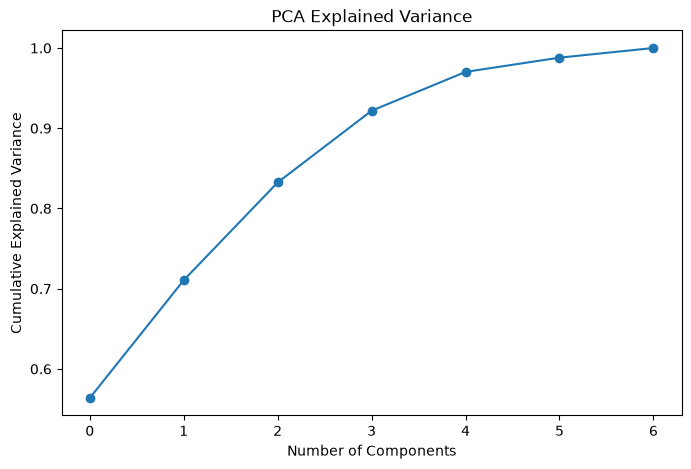

In [13]:
pca = PCA()

pca_data = pca.fit_transform(scaled_data)

plt.figure(figsize=(8,5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.show()

In [14]:
pca = PCA(n_components=2)

pca_results = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_results,
    columns=['PC1','PC2']
)

In [ ]:
PCA

# K-Means Clustering

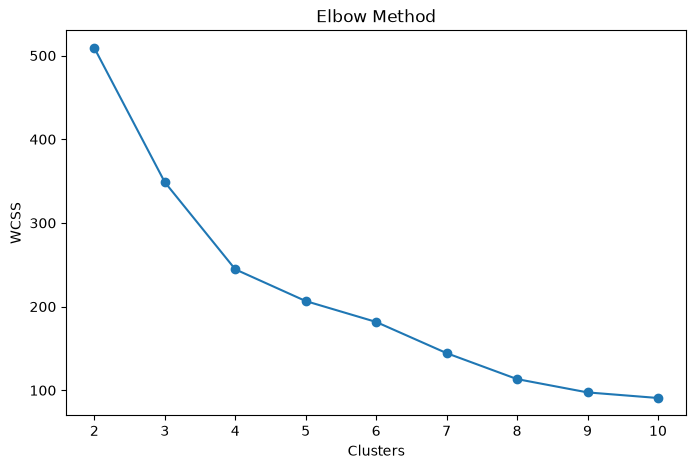

In [15]:
wcss = []

for i in range(2,11):

    km = KMeans(
        n_clusters=i,
        random_state=42
    )

    km.fit(pca_df)

    wcss.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), wcss, marker='o')
plt.xlabel("Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [17]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

clusters = kmeans.fit_predict(pca_df)

pca_df['Cluster'] = clusters

cluster_by_country = pd.Series(clusters, index=country_names)
latest_df['Cluster'] = latest_df['country_name'].map(cluster_by_country)

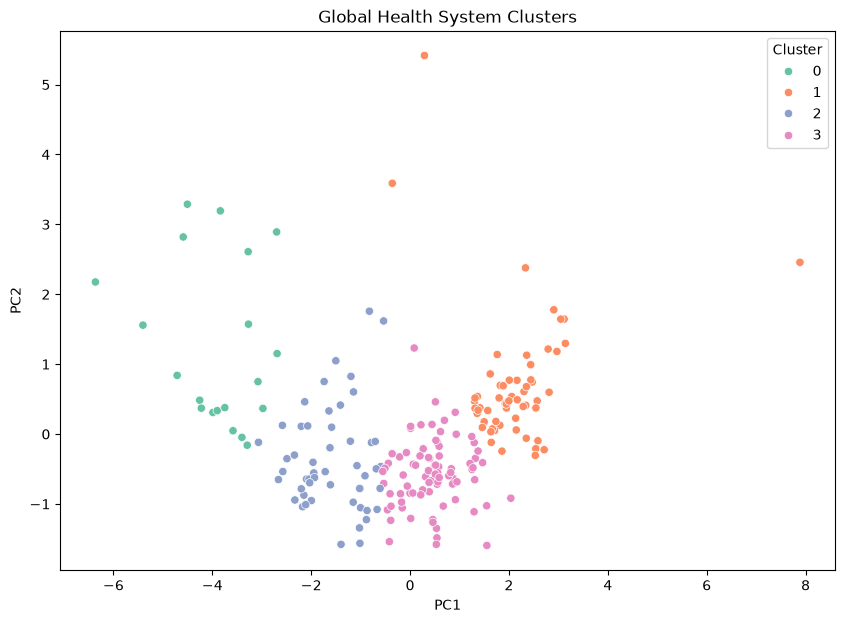

In [18]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=pca_df,
    palette='Set2'
)

plt.title("Global Health System Clusters")
plt.show()

In [20]:
country_data.assign(Cluster=cluster_by_country).groupby('Cluster')[selected_features].mean()

indicator_code,life_expectancy,maternal_mortality,under5_mortality,health_expenditure_pct_gdp,gdp_per_capita,physicians_per_1000,hospital_beds_per_1000
Cluster,,,,,,,
0,60.845750,505.850000,80.140000,6.889176,978.820695,0.162400,0.674500
1,79.862053,19.344828,5.431034,9.276969,48265.306987,4.015207,5.111034
2,68.154981,170.653846,36.936538,5.248899,3140.708970,0.460981,1.416154
3,76.327419,40.759259,13.817901,5.893150,20418.801275,2.024383,2.574691


Interpret:

Cluster 0 = High-performing countries
Cluster 1 = Emerging systems
Cluster 2 = Developing systems
Cluster 3 = Vulnerable systems

# Time Series Forecasting

In [23]:
prophet_df = health_df.loc[
    health_df['country_name'].eq('Kenya'),
    ['year', 'life_expectancy']
].copy()

prophet_df.columns = ['ds', 'y']
prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'].astype(int).astype(str),
    format='%Y'
)

prophet_df.columns = ['ds','y']

prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'],
    format='%Y'
)

In [24]:
model = Prophet()

model.fit(prophet_df)

20:48:35 - cmdstanpy - INFO - Chain [1] start processing
20:48:36 - cmdstanpy - INFO - Chain [1] done processing


In [26]:
future = model.make_future_dataframe(
    periods=6,
    freq='YE'
)

forecast = model.predict(future)

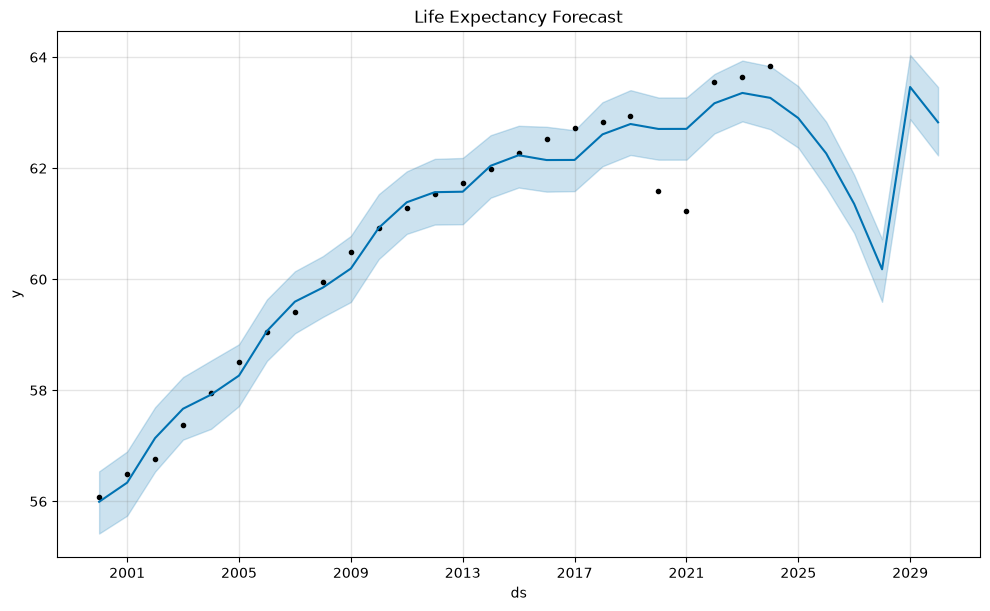

In [27]:
fig = model.plot(forecast)

plt.title(
    "Life Expectancy Forecast"
)

plt.show()

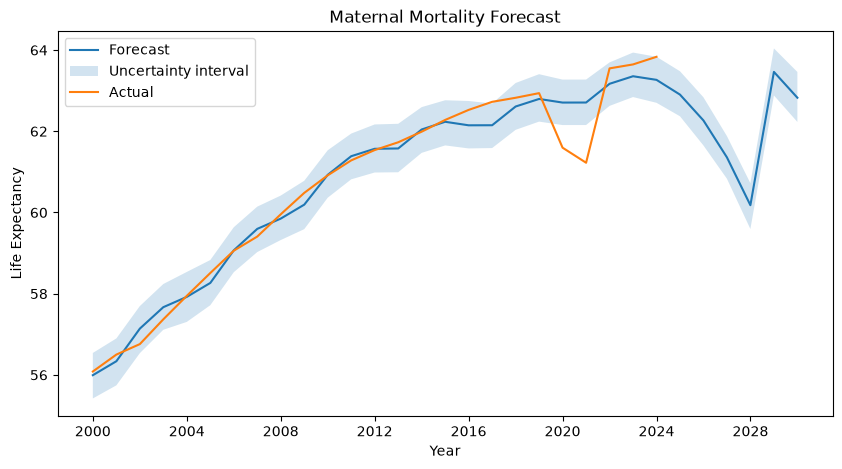

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(forecast['ds'], forecast['yhat'], label='Forecast')
plt.fill_between(
    forecast['ds'],
    forecast['yhat_lower'],
    forecast['yhat_upper'],
    alpha=0.2,
    label='Uncertainty interval'
)
plt.plot(prophet_df['ds'], prophet_df['y'], label='Actual')

plt.title("Maternal Mortality Forecast")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.legend()
plt.show()



In [28]:
actual = prophet_df['y']

predicted = forecast.iloc[
    :len(actual)
]['yhat']

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

mae = mean_absolute_error(
    actual,
    predicted
)

print("RMSE:", rmse)
print("MAE:", mae)


RMSE: 0.44849920348755684
MAE: 0.29375028864104935


# LSTM Forecasting

In [30]:
series = prophet_df['y'].to_numpy(dtype=float)

In [31]:
scaler = MinMaxScaler()

scaled = scaler.fit_transform(
    series.reshape(-1,1)
)

In [32]:
def create_sequences(
    data,
    window=3
):

    X = []
    y = []

    for i in range(
        len(data)-window
    ):

        X.append(
            data[i:i+window]
        )

        y.append(
            data[i+window]
        )

    return np.array(X), np.array(y)

X,y = create_sequences(
    scaled,
    3
)

In [33]:
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

In [34]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(3,1)
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    LSTM(32)
)

model.add(
    Dense(1)
)

model.compile(
    optimizer='adam',
    loss='mse'
)

history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=4,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 467ms/step - loss: 0.4707
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.3481 
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.2270
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1158
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0329
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0194
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0286
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0123
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0125 
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0149
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0126
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0116
Epoch 13/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0116
Epoch 14/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0106
Epoch 15/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0094 
Epoch 16/100
6/

In [35]:
predictions = model.predict(X)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(y)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step


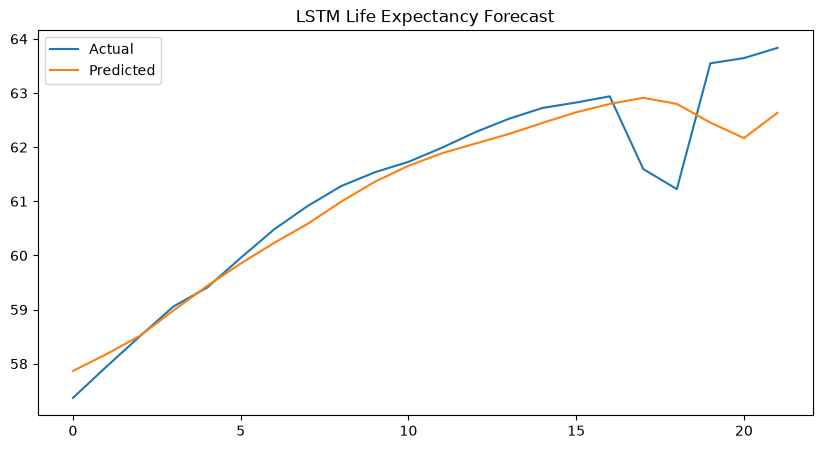

In [36]:
plt.figure(figsize=(10,5))

plt.plot(
    actual,
    label="Actual"
)

plt.plot(
    predictions,
    label="Predicted"
)

plt.legend()

plt.title(
    "LSTM Life Expectancy Forecast"
)

plt.show()

In [37]:
last_sequence = scaled[-3:]

future_predictions = []

for _ in range(6):

    pred = model.predict(
        last_sequence.reshape(1,3,1),
        verbose=0
    )

    future_predictions.append(
        pred[0,0]
    )

    last_sequence = np.append(
        last_sequence[1:],
        pred
    )

In [38]:
future_predictions = scaler.inverse_transform(
    np.array(
        future_predictions
    ).reshape(-1,1)
)

future_predictions

array([[63.528027],
       [63.568764],
       [63.566334],
       [63.46711 ],
       [63.46819 ],
       [63.443207]], dtype=float32)